# Customer Credit Risk — Data Preprocessing & Feature Engineering
**End-to-end practical project | Synthetic teaching dataset | 1,500 customers**

> This is a reproducible educational dataset generated for the assignment. It is not real customer data and must not be used for lending decisions.

## Objective
Prepare a consistent dataset for predicting loan default (`default_flag`: 0 = No, 1 = Yes). The workflow follows the assignment: acquisition, understanding, profiling, missing-value treatment, outliers, encoding, numerical binning, scaling, transformations, feature construction and final export.

### Dataset fields
`customer_id`, `age`, `gender`, `region`, `education_level`, `employment_type`, `annual_income`, `loan_amount`, `loan_purpose`, `credit_score`, `repayment_history`, `transaction_count`, `spending_ratio`, `join_date`, `default_flag`.

## 1. Setup and reproducibility
Install requirements with `pip install -r requirements.txt` if needed. Run cells from top to bottom.

In [1]:
import os, json, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler,
    MinMaxScaler, MaxAbsScaler, RobustScaler, Normalizer, FunctionTransformer,
    PowerTransformer, Binarizer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.cluster import KMeans
from scipy.stats.mstats import winsorize
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_DIR = "data"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_columns", 50)

## 2. Data acquisition from multiple sources
The main customer table is read from CSV. Metadata is parsed from JSON. Repayment details are loaded from SQLite (the CSV is first imported into a small local database). A dummy API response is represented by a local Python dictionary so the project works offline.

In [2]:
customers = pd.read_csv(f"{DATA_DIR}/customer_credit_risk.csv")
with open(f"{DATA_DIR}/customer_metadata.json", "r") as f:
    metadata = pd.DataFrame(json.load(f))
repayment_source = pd.read_csv(f"{DATA_DIR}/repayment_history_source.csv")
# Create/read a local SQL table to demonstrate SQL acquisition.
con = sqlite3.connect(":memory:")
repayment_source.to_sql("repayment_history", con, index=False, if_exists="replace")
sql_repayment = pd.read_sql_query("SELECT * FROM repayment_history", con)
# Offline dummy API response: external economic indicator by customer region.
api_payload = {"indicators":[
    {"region":"North","regional_unemployment_rate":6.2},
    {"region":"South","regional_unemployment_rate":5.1},
    {"region":"East","regional_unemployment_rate":7.4},
    {"region":"West","regional_unemployment_rate":5.8}
]}
api_data = pd.DataFrame(api_payload["indicators"])
df = (customers.merge(metadata, on="customer_id", how="left")
      .merge(sql_repayment[["customer_id","on_time_payment_rate"]], on="customer_id", how="left")
      .merge(api_data, on="region", how="left"))
print("CSV:", customers.shape, "| JSON:", metadata.shape, "| SQL:", sql_repayment.shape, "| API:", api_data.shape)
print("Merged dataset:", df.shape)
display(df.head())

CSV: (1500, 15) | JSON: (1500, 3) | SQL: (1500, 3) | API: (4, 2)
Merged dataset: (1500, 19)


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag,digital_profile,channel,on_time_payment_rate,regional_unemployment_rate
0,C100000,43.0,Female,South,Primary,Salaried,407649.50,302159.65,Car,1100.0,0,46,35.76,2020-12-19,0,Medium,Branch,0.983,5.1
1,C100001,27.0,Male,West,Primary,Salaried,780840.63,382146.92,Home,701.0,2,42,18.04,2016-03-07,1,High,Mobile,0.851,5.8
2,C100002,48.0,Male,West,Post-Graduate,Self-Employed,590335.53,433341.03,Business,NaN,2,40,49.19,2015-11-09,1,Low,Mobile,0.857,5.8
3,C100003,50.0,Male,South,Graduate,Unemployed,344032.64,280671.23,Car,775.0,2,51,25.51,2021-09-09,1,Medium,Mobile,0.937,5.1
4,C100004,18.0,Male,East,Secondary,Salaried,1041656.91,497371.10,Other,NaN,0,40,29.33,2018-12-02,0,Low,Branch,1.000,7.4


## 3. Data understanding and quality checks
`info()` reports types and non-null counts; `describe()` summarizes numerical variables. The following tables quantify missing values, duplicates, and target balance.

In [3]:
df.info()
display(df.describe(include="all").T)
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean()*100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)
display(quality)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
display(df["default_flag"].value_counts().rename(index={0:"No Default",1:"Default"}).to_frame("count"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 1500 non-null   object 
 1   age                         1433 non-null   float64
 2   gender                      1448 non-null   object 
 3   region                      1500 non-null   object 
 4   education_level             1500 non-null   object 
 5   employment_type             1410 non-null   object 
 6   annual_income               1425 non-null   float64
 7   loan_amount                 1500 non-null   float64
 8   loan_purpose                1500 non-null   object 
 9   credit_score                1441 non-null   float64
 10  repayment_history           1500 non-null   int64  
 11  transaction_count           1500 non-null   int64  
 12  spending_ratio              1500 non-null   float64
 13  join_date                   1500 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1500,1500,C100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1433.0,NaN,NaN,NaN,38.888346,11.502251,18.0,31.0,39.0,46.0,75.0
gender,1448,3,Male,712,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1500,4,North,431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,1500,4,Graduate,578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,1410,3,Salaried,897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income,1425.0,NaN,NaN,NaN,892861.446723,908226.98596,103356.66,505272.76,711233.59,1024518.45,12538482.497759
loan_amount,1500.0,NaN,NaN,NaN,550596.301456,586717.988916,31700.98,235247.0475,421054.935,675544.54,9683871.409387
loan_purpose,1500,5,Home,449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_score,1441.0,NaN,NaN,NaN,678.667592,74.932839,120.0,635.0,677.0,719.0,1100.0


,dtype,missing_count,missing_percent,unique_values
employment_type,object,90,6.00,3
annual_income,float64,75,5.00,1425
age,float64,67,4.47,57
credit_score,float64,59,3.93,302
gender,object,52,3.47,3
customer_id,object,0,0.00,1500
education_level,object,0,0.00,4
region,object,0,0.00,4
loan_amount,float64,0,0.00,1500
loan_purpose,object,0,0.00,5


Duplicate rows: 0
Duplicate customer IDs: 0


,count
default_flag,
No Default,1239
Default,261


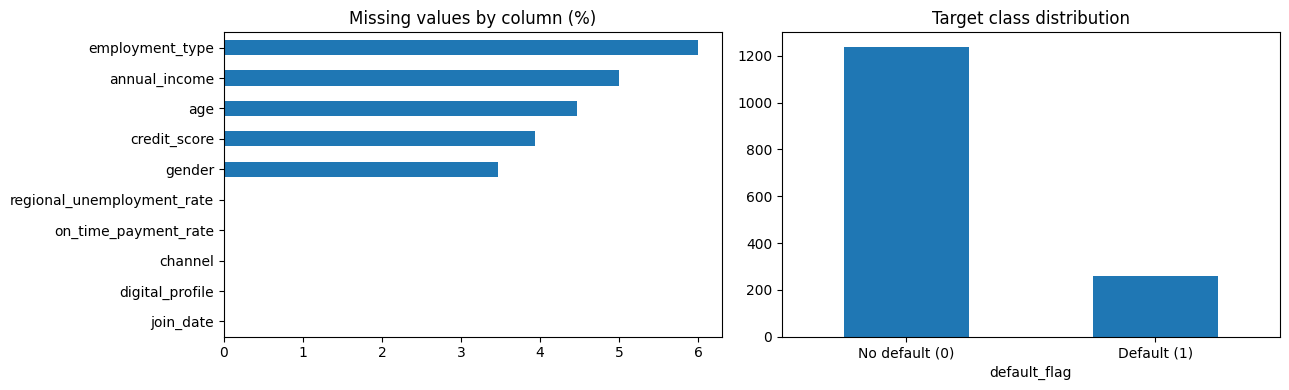

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
quality.sort_values("missing_percent").tail(10)["missing_percent"].plot(kind="barh", ax=axes[0], title="Missing values by column (%)")
df["default_flag"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Target class distribution", rot=0)
axes[1].set_xticklabels(["No default (0)","Default (1)"])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_data_quality.png", dpi=150); plt.show()

**Interpretation:** Missingness was deliberately introduced in selected demographic and financial fields to make imputation exercises possible. The target distribution is not guaranteed to be balanced; class imbalance should be checked before model training.

## 4. Missing-value treatment: compare strategies
The assignment asks for mean/median, most-frequent, missing-indicator plus random-sample, KNN, MICE and complete-case analysis. We compare approaches on copies rather than overwriting the original source table. The target and ID are not imputed.

In [5]:
numeric_for_impute = ["age","annual_income","loan_amount","credit_score","repayment_history","transaction_count","spending_ratio"]
categorical_for_impute = ["gender","employment_type"]
# A. Simple imputation: median for numeric, most frequent for categorical.
simple = df.copy()
simple[numeric_for_impute] = SimpleImputer(strategy="median").fit_transform(simple[numeric_for_impute])
simple[categorical_for_impute] = SimpleImputer(strategy="most_frequent").fit_transform(simple[categorical_for_impute])
# B. Most-frequent category imputation, explicitly for gender.
gender_mode = df["gender"].mode(dropna=True)[0]
mode_gender = df["gender"].fillna(gender_mode)
# C. Missing indicator + random-sample imputation for annual income.
income_random = df["annual_income"].copy()
income_missing_flag = income_random.isna().astype(int)
observed_income = income_random.dropna().to_numpy()
income_random.loc[income_random.isna()] = np.random.default_rng(RANDOM_STATE).choice(observed_income, size=income_random.isna().sum(), replace=True)
# D. KNN imputation on selected numerical variables.
knn_values = KNNImputer(n_neighbors=5, weights="distance").fit_transform(df[numeric_for_impute])
knn_result = pd.DataFrame(knn_values, columns=numeric_for_impute, index=df.index)
# E. MICE / IterativeImputer (multivariate chained-equation-style estimation).
mice_values = IterativeImputer(random_state=RANDOM_STATE, max_iter=10).fit_transform(df[numeric_for_impute])
mice_result = pd.DataFrame(mice_values, columns=numeric_for_impute, index=df.index)
# F. Complete-case analysis: drop rows with any missing values in selected analysis fields.
complete_case = df.dropna(subset=numeric_for_impute + categorical_for_impute)
comparison = pd.DataFrame({
    "method":["Original selected fields","Simple median/mode","KNN numerical","MICE numerical","Complete-case rows"],
    "remaining_missing":[int(df[numeric_for_impute+categorical_for_impute].isna().sum().sum()),
        int(simple[numeric_for_impute+categorical_for_impute].isna().sum().sum()),
        int(knn_result.isna().sum().sum()),
        int(mice_result.isna().sum().sum()), int(complete_case[numeric_for_impute+categorical_for_impute].isna().sum().sum())],
    "rows_available":[len(df),len(simple),len(knn_result),len(mice_result),len(complete_case)]
})
display(comparison)
print("Gender mode used:", gender_mode)
print("Annual income missing indicator count:", income_missing_flag.sum())

,method,remaining_missing,rows_available
0,Original selected fields,343,1500
1,Simple median/mode,0,1500
2,KNN numerical,0,1500
3,MICE numerical,0,1500
4,Complete-case rows,0,1180


Gender mode used: Male
Annual income missing indicator count: 75


**Interpretation:** Median imputation is robust to skew and extreme values; mode is suitable for nominal categories. KNN and MICE use relationships among numerical columns and can preserve multivariate patterns, but require scaling/appropriate variable selection in a production workflow. Random-sample imputation retains the observed distribution and the missingness flag preserves information that a value was absent. Complete-case analysis is simple but reduces sample size and can introduce bias when missingness is systematic.

## 5. Outlier detection and treatment
Methods: Z-score (|z| > 3), IQR fences, percentile caps and Winsorization. Extreme values may be genuine high-risk customers, so flagging and domain review are preferable to blindly deleting observations.

In [6]:
outlier_cols = ["annual_income","loan_amount","credit_score","spending_ratio"]
outlier_rows = []
for col in outlier_cols:
    s = df[col].dropna()
    z = (s-s.mean())/s.std(ddof=0)
    q1,q3 = s.quantile([.25,.75]); iqr=q3-q1
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    p1,p99=s.quantile([.01,.99])
    outlier_rows.append([col,int((z.abs()>3).sum()),int(((s<lower)|(s>upper)).sum()),round(p1,2),round(p99,2)])
outlier_summary = pd.DataFrame(outlier_rows, columns=["feature","zscore_count","iqr_count","p01","p99"])
display(outlier_summary)

,feature,zscore_count,iqr_count,p01,p99
0,annual_income,16,67,190959.47,3961736.61
1,loan_amount,17,82,50687.69,2418569.18
2,credit_score,12,28,528.80,848.60
3,spending_ratio,1,2,4.09,72.65


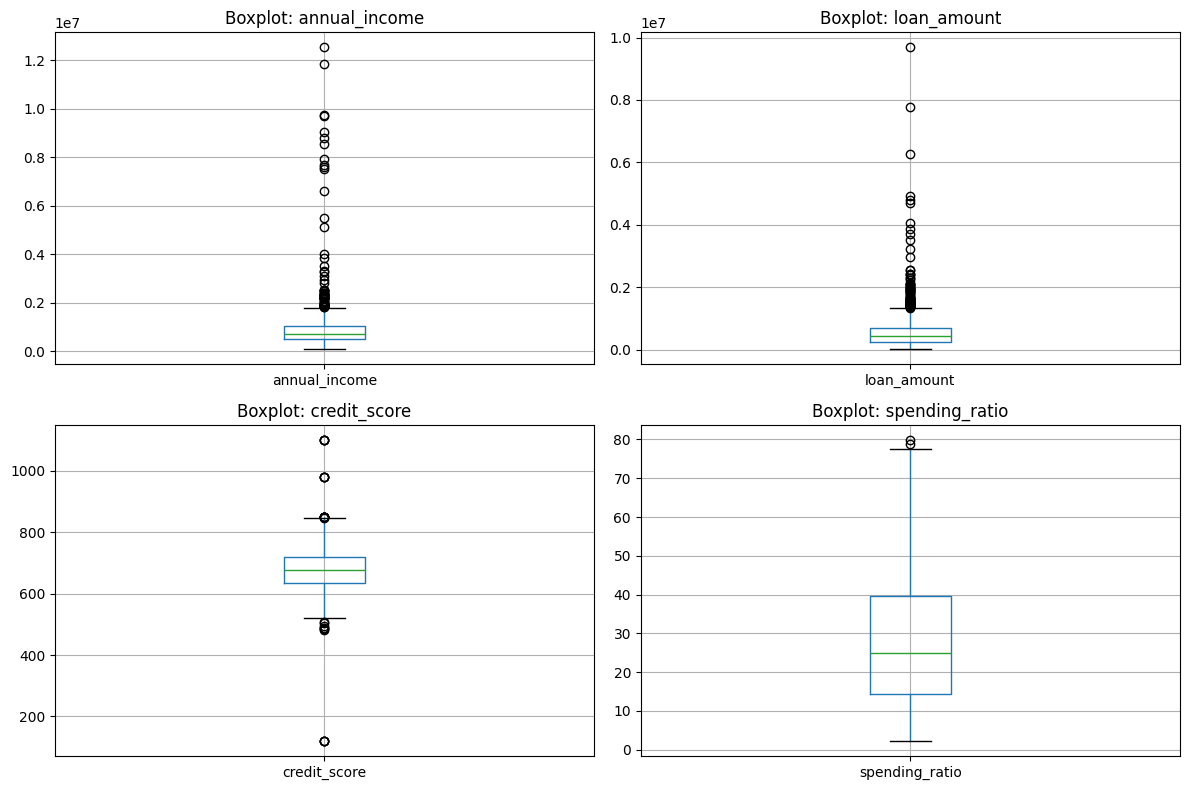

In [7]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.ravel(),outlier_cols):
    df.boxplot(column=col, ax=ax); ax.set_title(f"Boxplot: {col}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/02_outlier_boxplots.png",dpi=150); plt.show()

In [8]:
outlier_treated = simple.copy()
for col in outlier_cols:
    lo, hi = outlier_treated[col].quantile([.01,.99])
    outlier_treated[col] = outlier_treated[col].clip(lo,hi)  # percentile capping
# Winsorization demonstration (5% tails) on annual_income.
winsor_income = pd.Series(winsorize(outlier_treated["annual_income"], limits=[.05,.05]), index=outlier_treated.index)
# Z-score and IQR flags for annual income, before treatment.
s = simple["annual_income"]
zflag = ((s-s.mean())/s.std(ddof=0)).abs()>3
q1,q3=s.quantile([.25,.75]); iqr=q3-q1
iqrflag = (s < q1-1.5*iqr) | (s > q3+1.5*iqr)
print("Annual income Z-score flags:", int(zflag.sum()))
print("Annual income IQR flags:", int(iqrflag.sum()))
print("Annual income 1st/99th percentile caps:", tuple(outlier_treated["annual_income"].quantile([.01,.99]).round(2)))

Annual income Z-score flags: 16
Annual income IQR flags: 76
Annual income 1st/99th percentile caps: (299018.15, 1753403.35)


**Interpretation:** Z-score is useful for roughly symmetric distributions; IQR is more robust for skewed data. Percentile capping and Winsorization limit the influence of extremes while retaining rows. For skewed income and loan amounts, IQR/percentile methods are often more defensible than assuming normality.

## 6. Mixed variables, date features and categorical encoding
Ordinal encoding preserves the known education order. One-hot encoding avoids imposing a false order on region and loan purpose. Gender is label-encoded for demonstration only; for nominal multi-class features, one-hot encoding is usually safer.

In [9]:
work = outlier_treated.copy()
# Date/time feature extraction.
work["join_date"] = pd.to_datetime(work["join_date"], errors="coerce")
work["join_year"] = work["join_date"].dt.year
work["join_month"] = work["join_date"].dt.month
work["join_day"] = work["join_date"].dt.day
work["join_weekday"] = work["join_date"].dt.dayofweek
# Ordinal encoding with explicit semantic order.
education_order = ["Primary","Secondary","Graduate","Post-Graduate"]
work["education_encoded"] = OrdinalEncoder(categories=[education_order]).fit_transform(work[["education_level"]])
# Label encoding example for gender; missing already handled in simple/outlier_treated.
gender_categories = {v:i for i,v in enumerate(sorted(work["gender"].dropna().unique()))}
work["gender_label"] = work["gender"].map(gender_categories)
# One-hot encoding for region and loan purpose.
onehot = pd.get_dummies(work[["region","loan_purpose"]], prefix=["region","purpose"], dtype=int)
display(pd.DataFrame({"education":education_order,"ordinal_code":range(len(education_order))}))
display(pd.DataFrame({"gender":list(gender_categories.keys()),"label":list(gender_categories.values())}))
display(onehot.head())

,education,ordinal_code
0,Primary,0
1,Secondary,1
2,Graduate,2
3,Post-Graduate,3


,gender,label
0,Female,0
1,Male,1
2,Other,2


,region_East,region_North,region_South,region_West,purpose_Business,purpose_Car,purpose_Education,purpose_Home,purpose_Other
0,0,0,1,0,0,1,0,0,0
1,0,0,0,1,0,0,0,1,0
2,0,0,0,1,1,0,0,0,0
3,0,0,1,0,0,1,0,0,0
4,1,0,0,0,0,0,0,0,1


## 7. Numerical encoding: binning and binarization
Income is discretized into quantile groups; missed payments use interpretable risk bands; transaction count uses K-Means clusters; credit score is binarized at the assignment's example threshold of 700.

In [10]:
work["income_quantile_bin"] = pd.qcut(work["annual_income"], q=4, labels=["Q1_Low","Q2_MidLow","Q3_MidHigh","Q4_High"], duplicates="drop")
work["missed_payment_band"] = pd.cut(work["repayment_history"], bins=[-1,0,2,100], labels=["None","1-2","3+"])
work["credit_score_gt_700"] = (work["credit_score"] > 700).astype(int)
km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
work["transaction_kmeans_bin"] = km.fit_predict(work[["transaction_count"]])
display(work[["annual_income","income_quantile_bin","repayment_history","missed_payment_band","credit_score","credit_score_gt_700","transaction_count","transaction_kmeans_bin"]].head(10))
display(work.groupby("income_quantile_bin", observed=False)["default_flag"].agg(["count","mean"]).rename(columns={"mean":"default_rate"}))

,annual_income,income_quantile_bin,repayment_history,missed_payment_band,credit_score,credit_score_gt_700,transaction_count,transaction_kmeans_bin
0,407649.50,Q1_Low,0.0,None,848.01,1,46.0,2
1,780840.63,Q3_MidHigh,2.0,1-2,701.00,1,42.0,2
2,590335.53,Q2_MidLow,2.0,1-2,677.00,0,40.0,2
3,344032.64,Q1_Low,2.0,1-2,775.00,1,51.0,1
4,1041656.91,Q4_High,0.0,None,677.00,0,40.0,2
5,528056.02,Q2_MidLow,1.0,1-2,624.00,0,45.0,2
6,575789.79,Q2_MidLow,2.0,1-2,642.00,0,35.0,0
7,558264.49,Q2_MidLow,2.0,1-2,569.00,0,32.0,0
8,1420500.34,Q4_High,2.0,1-2,660.00,0,40.0,2
9,703978.15,Q2_MidLow,2.0,1-2,649.00,0,43.0,2


,count,default_rate
income_quantile_bin,,
Q1_Low,375,0.178667
Q2_MidLow,413,0.179177
Q3_MidHigh,337,0.183976
Q4_High,375,0.154667


**Interpretation:** Binning can make patterns easier to communicate and reduce sensitivity to small numeric fluctuations, but it loses information. Quantile bins aim for similarly sized groups; K-Means bins are data-driven clusters and their numeric labels have no inherent ranking.

## 8. Feature scaling
Compare StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler and row-wise Normalizer. Scaling is fitted on training data only in the final modeling pipeline to avoid leakage.

In [11]:
scale_cols = ["age","annual_income","loan_amount","credit_score","repayment_history","transaction_count","spending_ratio"]
scale_data = work[scale_cols].copy()
scalers = {
    "StandardScaler":StandardScaler(),
    "MinMaxScaler":MinMaxScaler(),
    "MaxAbsScaler":MaxAbsScaler(),
    "RobustScaler":RobustScaler()
}
scale_comparison = []
for name, scaler in scalers.items():
    arr = scaler.fit_transform(scale_data)
    scale_comparison.append({"method":name,"mean_of_first_feature":arr[:,0].mean(),"std_of_first_feature":arr[:,0].std(),
                             "min_all":arr.min(),"max_all":arr.max()})
display(pd.DataFrame(scale_comparison).round(3))
normalized = Normalizer().fit_transform(scale_data)
print("Normalizer: first row L2 norm =", round(np.linalg.norm(normalized[0]),3))

,method,mean_of_first_feature,std_of_first_feature,min_all,max_all
0,StandardScaler,0.000,1.000,-3.077,5.461
1,MinMaxScaler,0.367,0.197,0.000,1.000
2,MaxAbsScaler,0.519,0.150,0.000,1.000
3,RobustScaler,-0.007,0.749,-2.424,4.537


Normalizer: first row L2 norm = 1.0


**Interpretation:** Standardization centers at mean 0 and standard deviation 1; Min-Max maps values to [0,1]; MaxAbs divides by maximum absolute value and preserves sparsity; RobustScaler uses median and IQR and is less affected by outliers. Normalizer scales each row to unit norm, not each feature—useful for vector direction, not a general replacement for feature scaling.

## 9. Transformations: log, reciprocal, square root, Box-Cox and Yeo-Johnson
`spending_ratio` is positive in this synthetic data. Box-Cox requires strictly positive values; Yeo-Johnson can handle zero/negative values. Transformations may reduce skewness but must be justified by diagnostics.

In [12]:
transform_cols = ["annual_income","loan_amount","spending_ratio"]
transform_demo = work[transform_cols].clip(lower=1).copy()
transformed = pd.DataFrame(index=work.index)
for col in transform_cols:
    transformed[col+"_log"] = np.log1p(transform_demo[col])
    transformed[col+"_sqrt"] = np.sqrt(transform_demo[col])
    transformed[col+"_reciprocal"] = 1/transform_demo[col]
boxcox = PowerTransformer(method="box-cox", standardize=False)
yeojohnson = PowerTransformer(method="yeo-johnson", standardize=False)
transformed["income_boxcox"] = boxcox.fit_transform(transform_demo[["annual_income"]]).ravel()
transformed["loan_yeojohnson"] = yeojohnson.fit_transform(work[["loan_amount"]]).ravel()
skew_table = pd.DataFrame({
    "feature":transform_cols,
    "skew_before":[work[c].skew() for c in transform_cols],
    "skew_log1p":[np.log1p(work[c].clip(lower=0)).skew() for c in transform_cols]
})
display(skew_table.round(3))

,feature,skew_before,skew_log1p
0,annual_income,0.921,0.031
1,loan_amount,1.925,-0.256
2,spending_ratio,0.651,-0.415


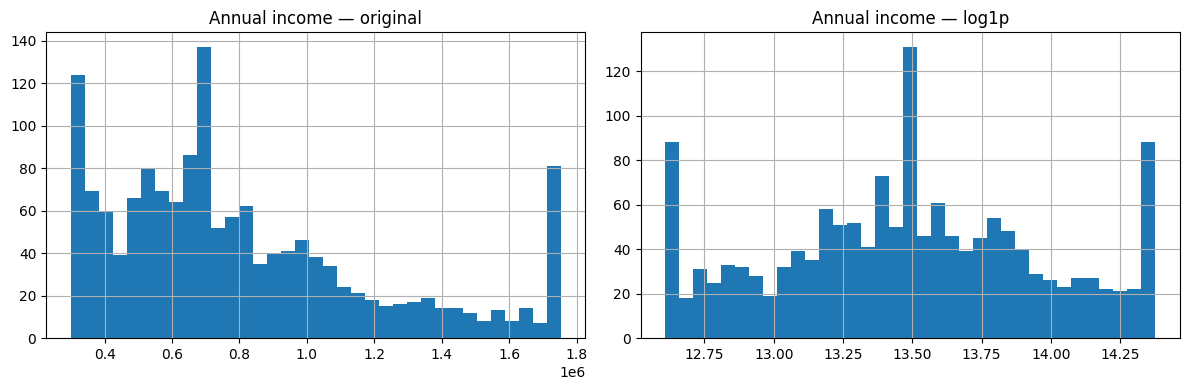

In [13]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
work["annual_income"].hist(bins=35,ax=axes[0]); axes[0].set_title("Annual income — original")
np.log1p(work["annual_income"]).hist(bins=35,ax=axes[1]); axes[1].set_title("Annual income — log1p")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_income_transformation.png",dpi=150); plt.show()

## 10. Feature construction
Create debt-to-income ratio, average monthly transactions and spending-to-income ratio. Ratios are protected against division by zero.

In [14]:
work["debt_to_income_ratio"] = work["loan_amount"] / work["annual_income"].replace(0,np.nan)
work["avg_monthly_transactions"] = work["transaction_count"] / 6
work["spending_to_income_ratio"] = (work["spending_ratio"] / 100)  # spending_ratio is supplied as a percentage
work["debt_to_income_ratio"] = work["debt_to_income_ratio"].replace([np.inf,-np.inf],np.nan)
display(work[["annual_income","loan_amount","debt_to_income_ratio","transaction_count","avg_monthly_transactions","spending_ratio","spending_to_income_ratio"]].head())

,annual_income,loan_amount,debt_to_income_ratio,transaction_count,avg_monthly_transactions,spending_ratio,spending_to_income_ratio
0,407649.50,302159.65,0.741224,46.0,7.666667,35.76,0.3576
1,780840.63,382146.92,0.489405,42.0,7.000000,18.04,0.1804
2,590335.53,433341.03,0.734059,40.0,6.666667,49.19,0.4919
3,344032.64,280671.23,0.815827,51.0,8.500000,25.51,0.2551
4,1041656.91,497371.10,0.477481,40.0,6.666667,29.33,0.2933


## 11. ColumnTransformer: separate numerical and categorical preprocessing
This is the recommended reusable pattern for mixed columns. We exclude the identifier, raw date, and target from model inputs. A train/test split is performed before fitting the transformer to prevent information leakage.

In [15]:
model_df = work.copy()
# Fill any remaining derived numeric gaps; raw input columns have been imputed above.
numeric_features = ["age","annual_income","loan_amount","credit_score","repayment_history","transaction_count",
                    "spending_ratio","join_year","join_month","join_day","join_weekday",
                    "debt_to_income_ratio","avg_monthly_transactions","spending_to_income_ratio"]
categorical_features = ["gender","region","education_level","employment_type","loan_purpose","income_quantile_bin","missed_payment_band"]
X = model_df[numeric_features + categorical_features].copy()
y = model_df["default_flag"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE,stratify=y)
numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",RobustScaler())
])
categorical_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num",numeric_pipeline,numeric_features),
    ("cat",categorical_pipeline,categorical_features)
])
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Train shape before:",X_train.shape,"after:",X_train_processed.shape)
print("Test shape before:",X_test.shape,"after:",X_test_processed.shape)
print("No missing values in transformed train matrix:", not np.isnan(X_train_processed.toarray() if hasattr(X_train_processed,"toarray") else X_train_processed).any())

Train shape before: (1200, 21) after: (1200, 40)
Test shape before: (300, 21) after: (300, 40)
No missing values in transformed train matrix: True


**Interpretation:** Numeric and categorical columns require different operations. The `ColumnTransformer` applies median imputation and robust scaling to numeric columns, and mode imputation plus one-hot encoding to categorical columns. It is fitted only on the training split; the test set is transformed using the already-fitted rules.

## 12. Final processed dataset and exports
The assignment requests a final cleaned/transformed dataset. The export below retains human-readable original columns plus engineered columns, while the model-ready feature matrix is exported separately. This distinction keeps the target and customer identifier auditable without feeding them into preprocessing.

In [16]:
final_clean = work.copy()
# Ensure all original imputation targets are complete in final human-readable table.
for col in numeric_for_impute:
    final_clean[col] = final_clean[col].fillna(final_clean[col].median())
for col in categorical_for_impute:
    final_clean[col] = final_clean[col].fillna(final_clean[col].mode()[0])
final_clean.to_csv(f"{OUT_DIR}/customer_credit_risk_cleaned_engineered.csv",index=False)
# Export encoded matrices with stable feature names.
feature_names = preprocessor.get_feature_names_out()
train_arr = X_train_processed.toarray() if hasattr(X_train_processed,"toarray") else X_train_processed
test_arr = X_test_processed.toarray() if hasattr(X_test_processed,"toarray") else X_test_processed
pd.DataFrame(train_arr,columns=feature_names,index=X_train.index).assign(default_flag=y_train).to_csv(f"{OUT_DIR}/model_train_processed.csv",index=False)
pd.DataFrame(test_arr,columns=feature_names,index=X_test.index).assign(default_flag=y_test).to_csv(f"{OUT_DIR}/model_test_processed.csv",index=False)
print("Final human-readable dataset:",final_clean.shape)
print("Model-ready training matrix:",train_arr.shape)
print("Model-ready test matrix:",test_arr.shape)
print("Files saved in outputs/")

Final human-readable dataset: (1500, 32)
Model-ready training matrix: (1200, 40)
Model-ready test matrix: (300, 40)
Files saved in outputs/


## 13. Final summary and limitations

In [17]:
summary = pd.DataFrame({
    "metric":["Original merged rows","Original merged columns","Rows in final clean export","Columns in final clean export",
              "Training rows","Test rows","Encoded model features","Default rate"],
    "value":[len(df),df.shape[1],len(final_clean),final_clean.shape[1],len(X_train),len(X_test),len(feature_names),round(y.mean(),4)]
})
display(summary)
display(final_clean[["default_flag","debt_to_income_ratio","avg_monthly_transactions","spending_to_income_ratio"]].describe().T)

,metric,value
0,Original merged rows,1500.000
1,Original merged columns,19.000
2,Rows in final clean export,1500.000
3,Columns in final clean export,32.000
4,Training rows,1200.000
5,Test rows,300.000
6,Encoded model features,40.000
7,Default rate,0.174


,count,mean,std,min,25%,50%,75%,max
default_flag,1500.0,0.174000,0.379236,0.000000,0.000000,0.000000,0.000000,1.000000
debt_to_income_ratio,1500.0,0.657197,0.407422,0.059787,0.363670,0.643902,0.881976,5.601442
avg_monthly_transactions,1500.0,7.015667,1.088649,3.666667,6.333333,7.000000,7.708333,10.500000
spending_to_income_ratio,1500.0,0.281363,0.169403,0.040898,0.144400,0.249000,0.397225,0.726505


### Conclusion
The project demonstrates a full preprocessing workflow on a synthetic customer credit-risk dataset. It covers multi-source acquisition, exploratory analysis, multiple missing-value approaches, four outlier techniques, categorical and numerical encoding, date extraction, five scaling methods, transformations, feature construction and a reusable `ColumnTransformer`.

### Important limitations
- All records are synthetic; patterns and model performance are educational only.
- Imputation and outlier rules should be selected using domain knowledge and training data only.
- Sensitive attributes such as gender should be assessed for fairness and legal compliance before any real credit decision system.
- A production credit-risk project also needs temporal validation, leakage checks, calibration, fairness testing, explainability, monitoring and governance.